# Smart Household Electricity Consumption Prediction Using Machine Learning
### Business Problem
Electricity providers and smart-home platforms need to know how much power a household will draw. Accurate prediction helps with:
- Lowering bills through smarter appliance scheduling
- Detecting abnormal usage (faulty appliances, leakage, theft)
- Grid load balancing and demand forecasting
- Personalised energy-saving recommendations

### Problem Statement
Predict the household's **Global Active Power (kW)** for a given minute using voltage, reactive power, sub-metering readings (kitchen, laundry, water-heater/AC), time-based features and recent past consumption (lags), targeting **R² ≥ 0.85**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r'household_power_consumption.csv.zip')

In [3]:
df.head()

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,0,1/1/07,0:00:00,2.58,0.136,241.97,10.6,0,0,0.0
1,1,1/1/07,0:01:00,2.552,0.1,241.75,10.4,0,0,0.0
2,2,1/1/07,0:02:00,2.55,0.1,241.64,10.4,0,0,0.0
3,3,1/1/07,0:03:00,2.55,0.1,241.71,10.4,0,0,0.0
4,4,1/1/07,0:04:00,2.554,0.1,241.98,10.4,0,0,0.0


In [4]:
df.tail()

,index,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
260635,260635,30/6/2007,23:55:00,2.88,0.36,239.01,12,0,0,18.0
260636,260636,30/6/2007,23:56:00,2.892,0.358,238.86,12.2,0,0,17.0
260637,260637,30/6/2007,23:57:00,2.882,0.28,239.05,12,0,0,18.0
260638,260638,30/6/2007,23:58:00,2.66,0.29,238.98,11.2,0,0,18.0
260639,260639,30/6/2007,23:59:00,2.548,0.354,239.25,10.6,0,1,17.0


In [5]:
df.shape

(260640, 10)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 260640 entries, 0 to 260639
Data columns (total 10 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   index                  260640 non-null  int64  
 1   Date                   260640 non-null  str    
 2   Time                   260640 non-null  str    
 3   Global_active_power    260640 non-null  str    
 4   Global_reactive_power  260640 non-null  str    
 5   Voltage                260640 non-null  str    
 6   Global_intensity       260640 non-null  str    
 7   Sub_metering_1         260640 non-null  str    
 8   Sub_metering_2         260640 non-null  str    
 9   Sub_metering_3         256869 non-null  float64
dtypes: float64(1), int64(1), str(8)
memory usage: 28.5 MB


### Data Cleaning

In [7]:
df = df.drop(columns=['index'])        
num_raw = ['Global_active_power','Global_reactive_power','Voltage','Global_intensity','Sub_metering_1','Sub_metering_2','Sub_metering_3']
for c in num_raw:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df.dtypes

Date                         str
Time                         str
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

In [8]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,256869.000000,256869.000000,256869.000000,256869.000000,256869.000000,256869.000000,256869.000000
mean,1.164937,0.123729,239.208981,4.974755,1.332481,1.670610,5.831825
std,1.181832,0.111872,3.592793,4.999493,6.704970,6.631361,8.186709
min,0.082000,0.000000,223.490000,0.400000,0.000000,0.000000,0.000000
25%,0.296000,0.000000,236.650000,1.400000,0.000000,0.000000,0.000000
50%,0.564000,0.104000,239.610000,2.600000,0.000000,0.000000,0.000000
75%,1.606000,0.194000,241.810000,6.800000,0.000000,1.000000,17.000000
max,10.670000,1.148000,250.890000,46.400000,78.000000,78.000000,20.000000


In [9]:
df.isnull().sum()

Date                        0
Time                        0
Global_active_power      3771
Global_reactive_power    3771
Voltage                  3771
Global_intensity         3771
Sub_metering_1           3771
Sub_metering_2           3771
Sub_metering_3           3771
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df = df.drop_duplicates()

### Date-Time Handling

In [12]:
df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], dayfirst=True, format='mixed')
df = df.sort_values('datetime').reset_index(drop=True)
df[['Date','Time','datetime']].head()

,Date,Time,datetime
0,1/1/07,0:00:00,2007-01-01 00:00:00
1,1/1/07,0:01:00,2007-01-01 00:01:00
2,1/1/07,0:02:00,2007-01-01 00:02:00
3,1/1/07,0:03:00,2007-01-01 00:03:00
4,1/1/07,0:04:00,2007-01-01 00:04:00


In [13]:
df['datetime'].min(), df['datetime'].max()

(Timestamp('2007-01-01 00:00:00'), Timestamp('2007-06-30 23:59:00'))

### Target Variable Analysis

In [14]:
df['Global_active_power'].describe()

count    256869.000000
mean          1.164937
std           1.181832
min           0.082000
25%           0.296000
50%           0.564000
75%           1.606000
max          10.670000
Name: Global_active_power, dtype: float64

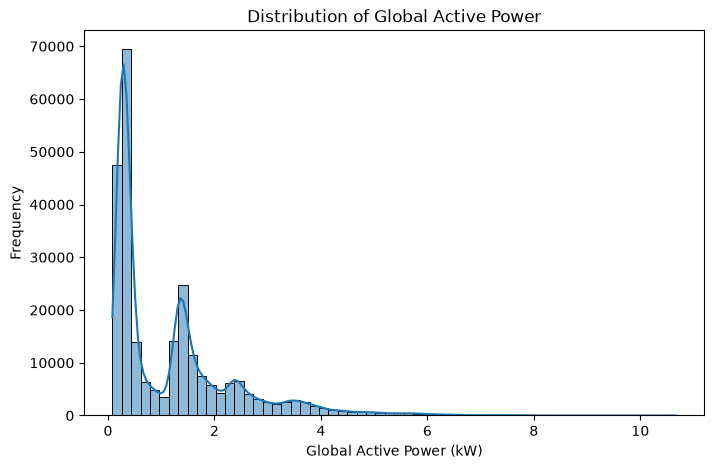

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(df['Global_active_power'].dropna(), kde=True, bins=60)
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of Global Active Power")
plt.show()

### Numerical Feature Analysis

In [16]:
df.select_dtypes(include=np.number).columns

Index(['Global_active_power', 'Global_reactive_power', 'Voltage',
       'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='str')

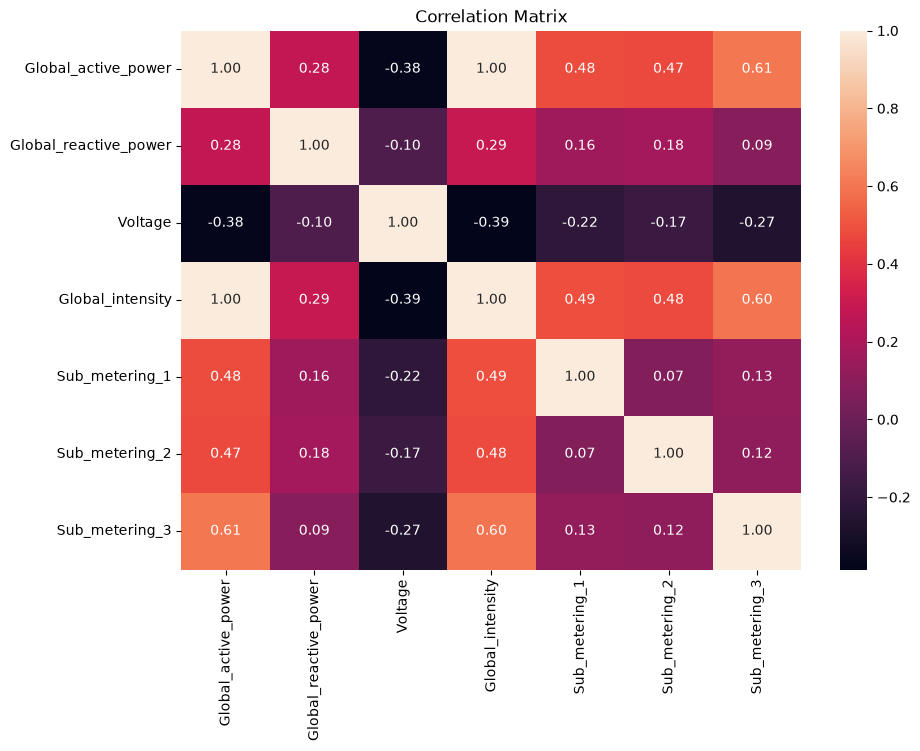

In [17]:
plt.figure(figsize=(10,7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

### Feature Engineering

In [18]:
df = df.set_index('datetime').asfreq('min')          
p = df['Global_active_power']
df['lag_1']        = p.shift(1)                       
df['lag_5']        = p.shift(5)
df['lag_15']       = p.shift(15)
df['lag_60']       = p.shift(60)                      
df['roll_mean_15'] = p.shift(1).rolling(15, min_periods=5).mean()
df['roll_mean_60'] = p.shift(1).rolling(60, min_periods=20).mean()
df['lag_1440']     = p.shift(1440)                    
df = df.reset_index().iloc[1440:].reset_index(drop=True)   
df[['datetime','Global_active_power','lag_1','lag_60','lag_1440']].head()

,datetime,Global_active_power,lag_1,lag_60,lag_1440
0,2007-01-02 00:00:00,0.442,0.460,0.372,2.580
1,2007-01-02 00:01:00,0.370,0.442,0.370,2.552
2,2007-01-02 00:02:00,0.368,0.370,0.396,2.550
3,2007-01-02 00:03:00,0.370,0.368,0.484,2.550
4,2007-01-02 00:04:00,0.370,0.370,0.480,2.554


In [19]:
df['hour']        = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.day_name().str.lower()
df['is_weekend']  = df['day_of_week'].isin(['saturday','sunday']).astype(int)

def time_of_day(h):
    if h < 6:  return 'night'
    if h < 12: return 'morning'
    if h < 18: return 'afternoon'
    return 'evening'
df['time_of_day'] = df['hour'].apply(time_of_day)

df['other_appliances'] = (df['Global_active_power']*1000/60
                          - df['Sub_metering_1'] - df['Sub_metering_2'] - df['Sub_metering_3'])
df[['datetime','hour','day_of_week','is_weekend','time_of_day']].head()

,datetime,hour,day_of_week,is_weekend,time_of_day
0,2007-01-02 00:00:00,0,tuesday,0,night
1,2007-01-02 00:01:00,0,tuesday,0,night
2,2007-01-02 00:02:00,0,tuesday,0,night
3,2007-01-02 00:03:00,0,tuesday,0,night
4,2007-01-02 00:04:00,0,tuesday,0,night


### Usage Patterns

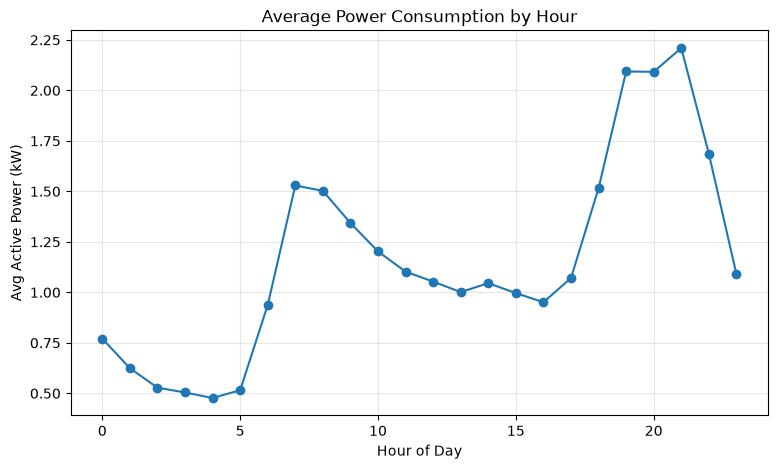

In [20]:
plt.figure(figsize=(9,5))
df.groupby('hour')['Global_active_power'].mean().plot(marker='o')
plt.xlabel("Hour of Day"); plt.ylabel("Avg Active Power (kW)")
plt.title("Average Power Consumption by Hour")
plt.grid(alpha=.3); plt.show()

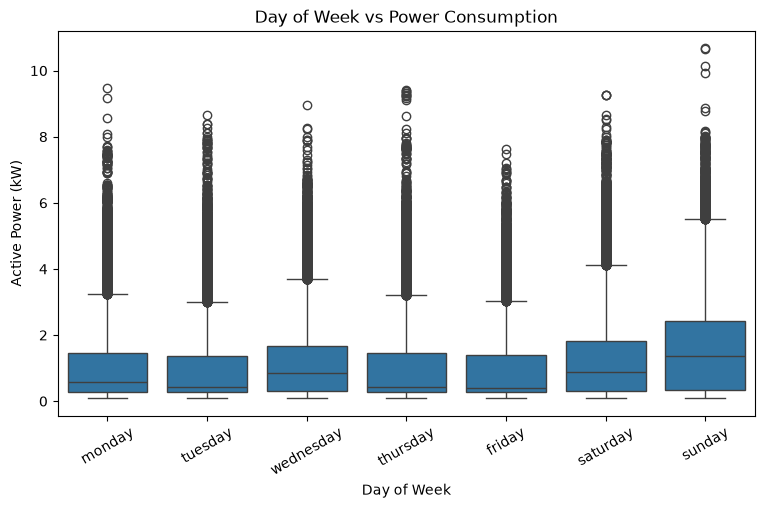

In [21]:
order = ['monday','tuesday','wednesday','thursday','friday','saturday','sunday']
plt.figure(figsize=(9,5))
sns.boxplot(x='day_of_week', y='Global_active_power', data=df, order=order)
plt.xticks(rotation=30)
plt.xlabel("Day of Week"); plt.ylabel("Active Power (kW)")
plt.title("Day of Week vs Power Consumption")
plt.show()

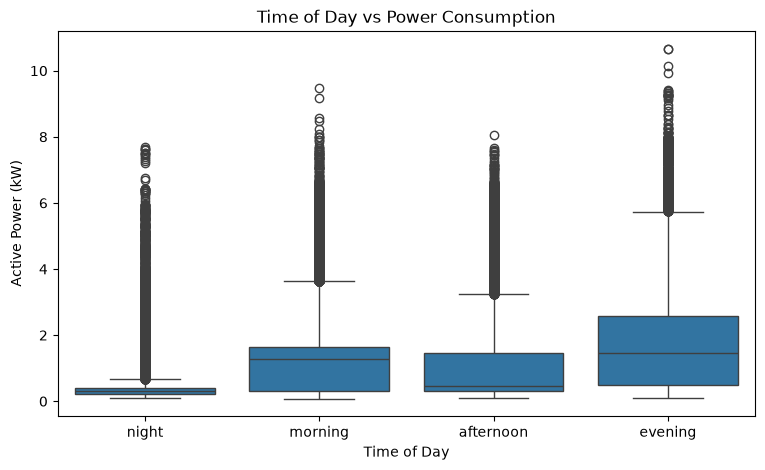

In [22]:
plt.figure(figsize=(9,5))
sns.boxplot(x='time_of_day', y='Global_active_power', data=df, order=['night','morning','afternoon','evening'])
plt.xlabel("Time of Day"); plt.ylabel("Active Power (kW)")
plt.title("Time of Day vs Power Consumption")
plt.show()

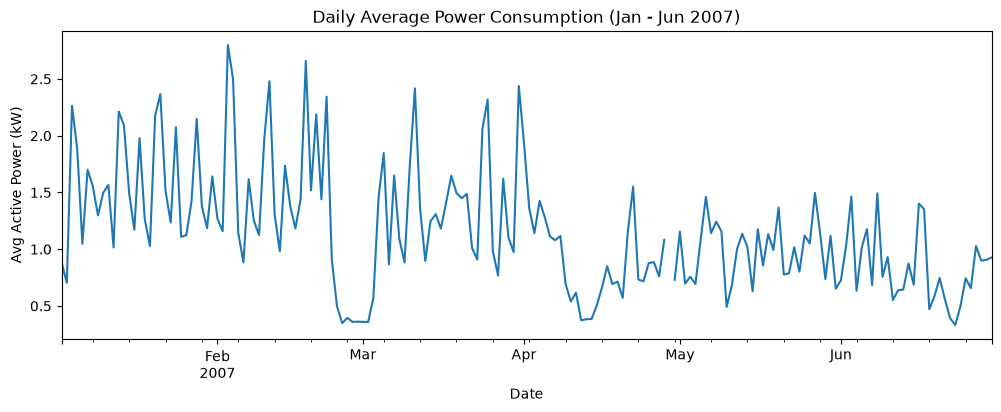

In [23]:
daily = df.set_index('datetime')['Global_active_power'].resample('D').mean()
plt.figure(figsize=(12,4))
daily.plot()
plt.xlabel("Date"); plt.ylabel("Avg Active Power (kW)")
plt.title("Daily Average Power Consumption (Jan - Jun 2007)")
plt.show()

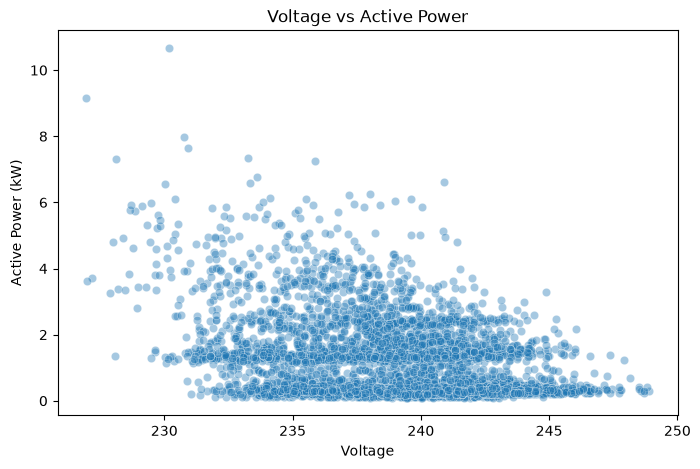

In [24]:
plt.figure(figsize=(8,5))
sns.scatterplot(x=df['Voltage'].sample(5000, random_state=42),
                y=df['Global_active_power'].sample(5000, random_state=42), alpha=.4)
plt.xlabel("Voltage"); plt.ylabel("Active Power (kW)")
plt.title("Voltage vs Active Power")
plt.show()

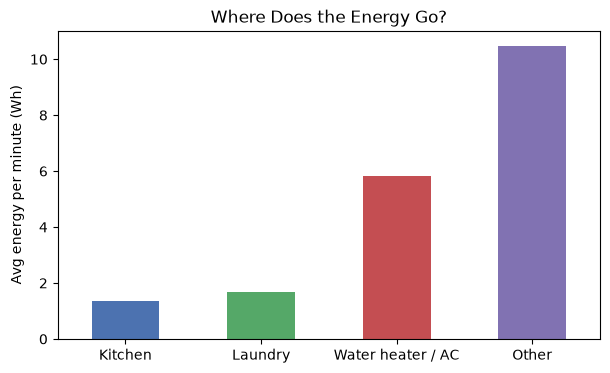

In [25]:
sub = df[['Sub_metering_1','Sub_metering_2','Sub_metering_3','other_appliances']].mean()
sub.index = ['Kitchen','Laundry','Water heater / AC','Other']
sub.plot(kind='bar', figsize=(7,4), color=['#4c72b0','#55a868','#c44e52','#8172b2'])
plt.ylabel("Avg energy per minute (Wh)")
plt.title("Where Does the Energy Go?")
plt.xticks(rotation=0); plt.show()

### Data Preprocessing

In [26]:
print("Rows with missing target:", df['Global_active_power'].isnull().sum())
df = df.dropna(subset=['Global_active_power']).reset_index(drop=True)
df.shape

Rows with missing target: 3771


(255429, 22)

In [27]:
X = df.drop(columns=['Global_active_power'])
y = df['Global_active_power']
X.shape, y.shape

((255429, 21), (255429,))

In [28]:
X = X.drop(columns=['Date','Time','datetime','Global_intensity','other_appliances'])
X.columns

Index(['Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3', 'lag_1', 'lag_5', 'lag_15', 'lag_60', 'roll_mean_15',
       'roll_mean_60', 'lag_1440', 'hour', 'day_of_week', 'is_weekend',
       'time_of_day'],
      dtype='str')

### Missing Values

In [29]:
X.isnull().sum()

Global_reactive_power       0
Voltage                     0
Sub_metering_1              0
Sub_metering_2              0
Sub_metering_3              0
lag_1                      13
lag_5                      22
lag_15                     42
lag_60                    108
roll_mean_15               10
roll_mean_60               20
lag_1440                 1488
hour                        0
day_of_week                 0
is_weekend                  0
time_of_day                 0
dtype: int64

In [30]:
y.isnull().sum()

np.int64(0)

In [31]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns
num_cols, cat_cols

(Index(['Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2',
        'Sub_metering_3', 'lag_1', 'lag_5', 'lag_15', 'lag_60', 'roll_mean_15',
        'roll_mean_60', 'lag_1440', 'hour', 'is_weekend'],
       dtype='str'),
 Index(['day_of_week', 'time_of_day'], dtype='str'))

### Train-Test Split

In [32]:
split = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((204343, 16), (51086, 16), (204343,), (51086,))

### Categorical Encoding (Ordinal + Nominal)

In [33]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
ordinal_cols = ['time_of_day']
nominal_cols = [c for c in cat_cols if c not in ordinal_cols]
ordinal_cols, nominal_cols

(['time_of_day'], ['day_of_week'])

In [34]:
ordinal_encoder = OrdinalEncoder(categories=[['night','morning','afternoon','evening']],
                                 handle_unknown='use_encoded_value', unknown_value=-1)
X_train_ord = ordinal_encoder.fit_transform(X_train[ordinal_cols])
X_test_ord  = ordinal_encoder.transform(X_test[ordinal_cols])
X_train_ord.shape, X_test_ord.shape

((204343, 1), (51086, 1))

In [35]:
nominal_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_nom = nominal_encoder.fit_transform(X_train[nominal_cols])
X_test_nom  = nominal_encoder.transform(X_test[nominal_cols])
X_train_nom.shape, X_test_nom.shape

((204343, 7), (51086, 7))

### Feature Scaling - StandardScaler

In [36]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_num_scaled = scaler.fit_transform(X_train[num_cols].fillna(X_train[num_cols].median()))
X_test_num_scaled  = scaler.transform(X_test[num_cols].fillna(X_train[num_cols].median()))
X_train_num_scaled.shape, X_test_num_scaled.shape

((204343, 14), (51086, 14))

### Preprocessing Using Pipeline

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [38]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [39]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [40]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [41]:
X_train_processed = preprocessor.fit_transform(X_train)
X_train_processed.shape

(204343, 25)

In [42]:
X_test_processed = preprocessor.transform(X_test)
X_test_processed.shape

(51086, 25)

### Model Building

In [43]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} Results")
    print("MSE  :", mse); print("RMSE :", rmse); print("MAE  :", mae); print("R2   :", r2)
    return mse, rmse, mae, r2

### Linear Regression

In [44]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](25,)","[ 0.01,-0.02, 0.09,..., 0.08,-0.02,-0.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.235
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,25
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(22)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](25,)","[1132.01, 511.44, 476. ,..., 0. , 0. , 0. ]"


In [45]:
y_pred_lr = lr.predict(X_test_processed)

In [46]:
mse_lr, rmse_lr, mae_lr, r2_lr = evaluate('Linear Regression', y_test, y_pred_lr)

Linear Regression Results
MSE  : 0.0715574704696111
RMSE : 0.2675022812418823
MAE  : 0.12010979750440388
R2   : 0.9236507518408982


### Decision Tree Regression

In [47]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 

In [48]:
y_pred_dt = dt.predict(X_test_processed)

In [49]:
mse_dt, rmse_dt, mae_dt, r2_dt = evaluate('Decision Tree Regression', y_test, y_pred_dt)

Decision Tree Regression Results
MSE  : 0.120303818580433
RMSE : 0.3468484086462456
MAE  : 0.1339571311122421
R2   : 0.8716401510701003


### Random Forest

In [50]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_processed, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [51]:
y_pred_rf = rf.predict(X_test_processed)

In [52]:
mse_rf, rmse_rf, mae_rf, r2_rf = evaluate('Random Forest Regression', y_test, y_pred_rf)

Random Forest Regression Results
MSE  : 0.04793883390714481
RMSE : 0.21894938663340624
MAE  : 0.09180366401753906
R2   : 0.9488509878505428


### Gradient Descent Regression

In [53]:
from sklearn.linear_model import SGDRegressor
sgd = SGDRegressor(max_iter=1000, learning_rate='invscaling', eta0=0.01, random_state=42)
sgd.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1


In [54]:
y_pred_sgd = sgd.predict(X_test_processed)

In [55]:
mse_sgd, rmse_sgd, mae_sgd, r2_sgd = evaluate('Gradient Descent Regression', y_test, y_pred_sgd)

Gradient Descent Regression Results
MSE  : 0.07291975560233718
RMSE : 0.2700365819705493
MAE  : 0.12206548498401988
R2   : 0.9221972425849201


### XGBoost Regression

In [56]:
!pip install xgboost

In [57]:
from xgboost import XGBRegressor
xgb = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                   subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
xgb.fit(X_train_processed, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [58]:
y_pred_xgb = xgb.predict(X_test_processed)

In [59]:
mse_xgb, rmse_xgb, mae_xgb, r2_xgb = evaluate('XGBoost Regression', y_test, y_pred_xgb)

XGBoost Regression Results
MSE  : 0.040614289733377724
RMSE : 0.20152987305453682
MAE  : 0.07987864842379208
R2   : 0.9566660131316941


### Gradient Boosting Regression

In [60]:
from sklearn.ensemble import GradientBoostingRegressor
gb = GradientBoostingRegressor(n_estimators=100, max_depth=5, random_state=42)
gb.fit(X_train_processed, y_train)

,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [61]:
y_pred_gb = gb.predict(X_test_processed)

In [62]:
mse_gb, rmse_gb, mae_gb, r2_gb = evaluate('Gradient Boosting Regression', y_test, y_pred_gb)

Gradient Boosting Regression Results
MSE  : 0.04377639416403905
RMSE : 0.2092280912402516
MAE  : 0.0800020671858257
R2   : 0.9532921613968974


In [63]:
results = pd.DataFrame({
    'Model': ['Linear Regression','Decision Tree','Random Forest','Gradient Descent','XGBoost','Gradient Boosting'],
    'MSE':  [mse_lr, mse_dt, mse_rf, mse_sgd, mse_xgb, mse_gb],
    'RMSE': [rmse_lr, rmse_dt, rmse_rf, rmse_sgd, rmse_xgb, rmse_gb],
    'MAE':  [mae_lr, mae_dt, mae_rf, mae_sgd, mae_xgb, mae_gb],
    'R2':   [r2_lr, r2_dt, r2_rf, r2_sgd, r2_xgb, r2_gb]
})
results

,Model,MSE,RMSE,MAE,R2
0,Linear Regression,0.071557,0.267502,0.120110,0.923651
1,Decision Tree,0.120304,0.346848,0.133957,0.871640
2,Random Forest,0.047939,0.218949,0.091804,0.948851
3,Gradient Descent,0.072920,0.270037,0.122065,0.922197
4,XGBoost,0.040614,0.201530,0.079879,0.956666
5,Gradient Boosting,0.043776,0.209228,0.080002,0.953292


### Cross-Validation

In [64]:
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=5)

In [65]:
cv_lr = cross_val_score(lr, X_train_processed, y_train, cv=tscv, scoring='neg_mean_squared_error')
print("Linear Regression CV RMSE:", np.sqrt(-cv_lr.mean()))

Linear Regression CV RMSE: 0.2827267213493537


In [66]:
cv_dt = cross_val_score(dt, X_train_processed, y_train, cv=tscv, scoring='neg_mean_squared_error')
print("Decision Tree CV RMSE:", np.sqrt(-cv_dt.mean()))

Decision Tree CV RMSE: 0.4268415714618833


In [67]:
cv_rf = cross_val_score(rf, X_train_processed, y_train, cv=tscv, scoring='neg_mean_squared_error', n_jobs=-1)
print("Random Forest CV RMSE:", np.sqrt(-cv_rf.mean()))

Random Forest CV RMSE: 0.27302771186313574


In [68]:
cv_sgd = cross_val_score(sgd, X_train_processed, y_train, cv=tscv, scoring='neg_mean_squared_error')
print("Gradient Descent CV RMSE:", np.sqrt(-cv_sgd.mean()))

Gradient Descent CV RMSE: 0.2835749628076493


In [69]:
cv_xgb = cross_val_score(xgb, X_train_processed, y_train, cv=tscv, scoring='neg_mean_squared_error')
print("XGBoost CV RMSE:", np.sqrt(-cv_xgb.mean()))

XGBoost CV RMSE: 0.2824003629320547


In [70]:
cv_gb = cross_val_score(gb, X_train_processed, y_train, cv=tscv, scoring='neg_mean_squared_error')
print("Gradient Boosting CV RMSE:", np.sqrt(-cv_gb.mean()))

Gradient Boosting CV RMSE: 0.2602116890985105


## Hyperparameter Tuning

In [71]:
from sklearn.model_selection import GridSearchCV

### XGBoost

In [72]:
xgb_params = {'max_depth': [4, 6],
              'learning_rate': [0.05, 0.1],
              'n_estimators': [200, 300]}
xgb_grid = GridSearchCV(XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
                        xgb_params, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=1)
xgb_grid.fit(X_train_processed, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1], 'max_depth': [4, 6], 'n_estimators': [200, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",Tr

In [73]:
print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

Best XGBoost Parameters:
{'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 200}


In [74]:
best_xgb = xgb_grid.best_estimator_
y_pred_best_xgb = best_xgb.predict(X_test_processed)

In [75]:
mse_best_xgb, rmse_best_xgb, mae_best_xgb, r2_best_xgb = evaluate('Tuned XGBoost', y_test, y_pred_best_xgb)

Tuned XGBoost Results
MSE  : 0.04137948154825441
RMSE : 0.20341947190044127
MAE  : 0.07919360192814932
R2   : 0.9558495809775119


### Model Selection

In [76]:
final_results = pd.DataFrame({
    'Model': ['XGBoost','Tuned XGBoost'],
    'MSE':  [ mse_xgb, mse_best_xgb],
    'RMSE': [rmse_xgb, rmse_best_xgb],
    'MAE':  [ mae_xgb, mae_best_xgb],
    'R2':   [ r2_xgb, r2_best_xgb]
})
final_results

,Model,MSE,RMSE,MAE,R2
0,XGBoost,0.040614,0.201530,0.079879,0.956666
1,Tuned XGBoost,0.041379,0.203419,0.079194,0.955850


In [77]:
final_results.sort_values(by='RMSE')

,Model,MSE,RMSE,MAE,R2
0,XGBoost,0.040614,0.201530,0.079879,0.956666
1,Tuned XGBoost,0.041379,0.203419,0.079194,0.955850


In [78]:
final_results.sort_values(by='R2', ascending=False)

,Model,MSE,RMSE,MAE,R2
0,XGBoost,0.040614,0.201530,0.079879,0.956666
1,Tuned XGBoost,0.041379,0.203419,0.079194,0.955850


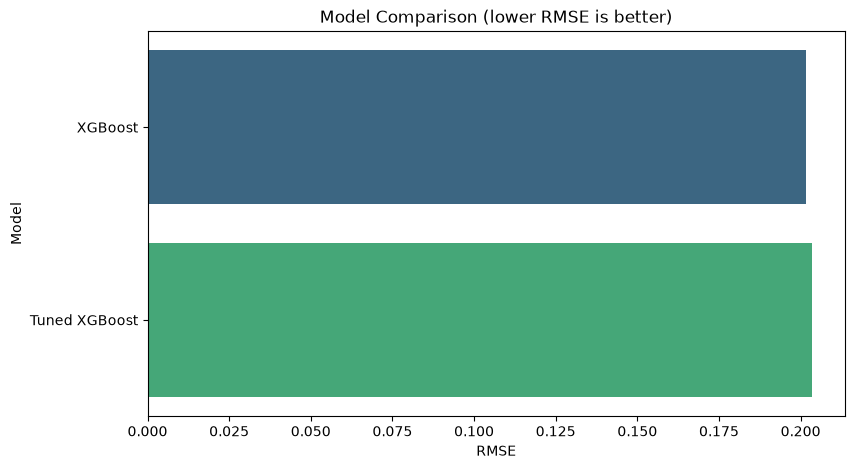

In [79]:
plt.figure(figsize=(9,5))
sns.barplot(y='Model', x='RMSE', hue='Model', data=final_results.sort_values('RMSE'), palette='viridis', legend=False)
plt.title("Model Comparison (lower RMSE is better)")
plt.show()

### Final Pipeline (best deployable model)

In [80]:
best_name = final_results.sort_values('RMSE').iloc[0]['Model']
print("Lowest test RMSE in the comparison table:", best_name)

compact_rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10,
                                   random_state=42, n_jobs=-1)
final_candidates = {'XGBoost': xgb,
                    'Tuned XGBoost': best_xgb,
                    'Compact Random Forest': compact_rf}
from sklearn.base import clone
final_scores = {}
for name, mdl in final_candidates.items():
    pipe = Pipeline([('preprocessing', preprocessor), ('model', clone(mdl))])
    pipe.fit(X_train, y_train)
    final_scores[name] = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
print(final_scores)
final_name = min(final_scores, key=final_scores.get)
print("Final model:", final_name)
final_model = final_candidates[final_name]

Lowest test RMSE in the comparison table: XGBoost
{'XGBoost': np.float64(0.20152987305453682), 'Tuned XGBoost': np.float64(0.20341947190044127), 'Compact Random Forest': np.float64(0.21990144763585073)}
Final model: XGBoost


In [81]:
from sklearn.base import clone
final_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', clone(final_model))
])
final_pipeline.fit(X_train, y_train)
y_pred_final = final_pipeline.predict(X_test)
mse_final, rmse_final, mae_final, r2_final = evaluate('Final Model', y_test, y_pred_final)

Final Model Results
MSE  : 0.040614289733377724
RMSE : 0.20152987305453682
MAE  : 0.07987864842379208
R2   : 0.9566660131316941


In [82]:
print("Target R2 >= 0.85 achieved:", r2_final >= 0.85, f"(R2 = {r2_final:.3f})")

Target R2 >= 0.85 achieved: True (R2 = 0.957)


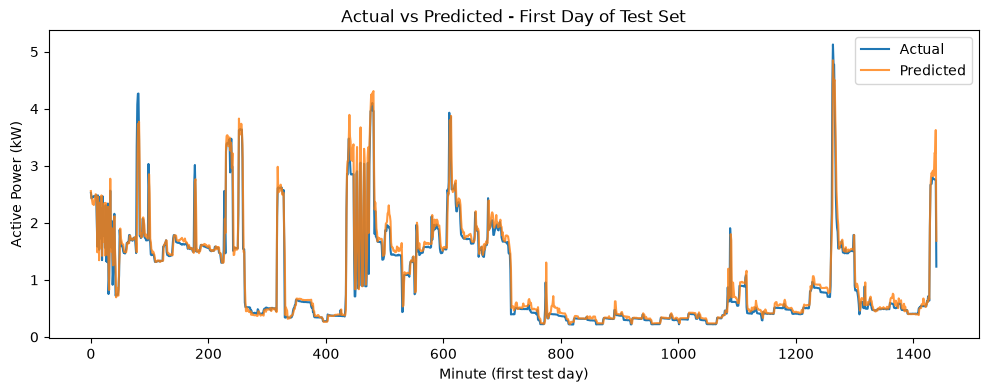

In [83]:
plt.figure(figsize=(12,4))
plt.plot(y_test.values[:1440], label='Actual')
plt.plot(y_pred_final[:1440], label='Predicted', alpha=.8)
plt.xlabel("Minute (first test day)"); plt.ylabel("Active Power (kW)")
plt.title("Actual vs Predicted - First Day of Test Set")
plt.legend(); plt.show()

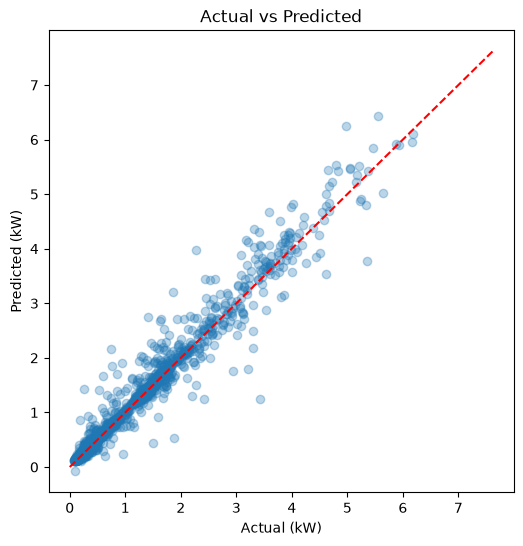

In [84]:
plt.figure(figsize=(6,6))
plt.scatter(y_test.values[::20], y_pred_final[::20], alpha=.3)
lims = [0, max(y_test.max(), y_pred_final.max())]
plt.plot(lims, lims, 'r--')
plt.xlabel("Actual (kW)"); plt.ylabel("Predicted (kW)")
plt.title("Actual vs Predicted")
plt.show()

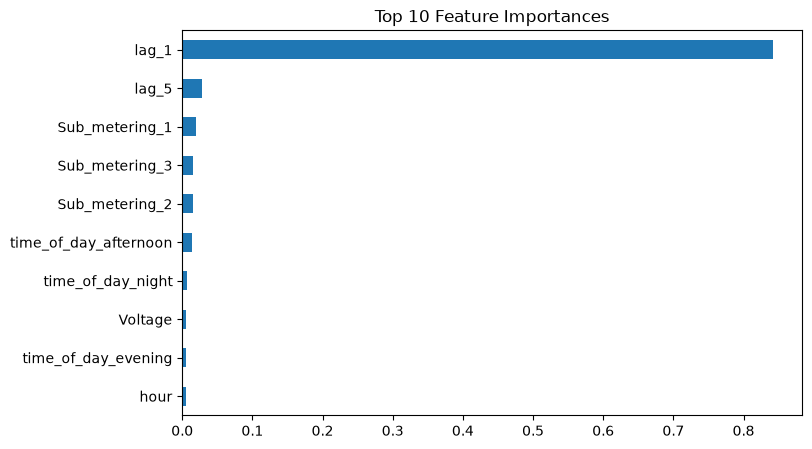

In [85]:
m = final_pipeline.named_steps['model']
if hasattr(m, 'feature_importances_'):
    names = list(num_cols) + list(final_pipeline.named_steps['preprocessing']
                                  .named_transformers_['cat'].named_steps['encoder']
                                  .get_feature_names_out(cat_cols))
    imp = pd.Series(m.feature_importances_, index=names).sort_values(ascending=False).head(10)
    imp.plot(kind='barh', figsize=(8,5)).invert_yaxis()
    plt.title("Top 10 Feature Importances"); plt.show()

### Deployment

In [86]:
import pickle
with open("electricity_consumption_model.pkl", "wb") as f:
    pickle.dump(final_pipeline, f)
print("electricity_consumption_model.pkl created successfully!")

electricity_consumption_model.pkl created successfully!


In [87]:
import os
print(os.path.exists("electricity_consumption_model.pkl"))
print(X_train.columns.tolist())

True
['Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'lag_1', 'lag_5', 'lag_15', 'lag_60', 'roll_mean_15', 'roll_mean_60', 'lag_1440', 'hour', 'day_of_week', 'is_weekend', 'time_of_day']


In [88]:
with open("electricity_consumption_model.pkl", "rb") as f:
    loaded = pickle.load(f)
loaded.predict(X_test.head(3)), y_test.head(3).values

(array([2.557103 , 2.4396632, 2.3979185], dtype=float32),
 array([2.526, 2.43 , 2.44 ]))

### Streamlit App

In [89]:
%%writefile app.py
import datetime as dt
import pickle
from pathlib import Path

import pandas as pd
import streamlit as st

BASE = Path(__file__).parent
MODEL_PATH = BASE / "electricity_consumption_model.pkl"
nan = float("nan")

st.set_page_config(page_title="Smart Household Electricity Prediction Using Machine Learning", page_icon="⚡", layout="wide")


@st.cache_resource
def load_model():
    with open(MODEL_PATH, "rb") as f:
        return pickle.load(f)


def time_of_day(hour):
    if hour < 6:
        return "night"
    if hour < 12:
        return "morning"
    if hour < 18:
        return "afternoon"
    return "evening"


st.markdown("<div style='background:#1f77b4;padding:26px;border-radius:12px;color:white;"
            "font-size:32px;font-weight:700'>Smart Household Electricity Consumption Prediction Using Machine Learning</div>",
            unsafe_allow_html=True)
st.write("")

if not MODEL_PATH.exists():
    st.error("`electricity_consumption_model.pkl` not found. Run the notebook cell that saves the pickle first.")
    st.stop()

model = load_model()
st.write("Enter the meter readings and the time to estimate the active power consumption.")

c1, c2, c3 = st.columns(3, gap="large")
with c1:
    st.subheader("Time")
    date = st.date_input("Date", value=dt.date.today())
    hour = st.slider("Hour (24h)", 0, 23, 19)
with c2:
    st.subheader("Electrical readings")
    voltage = st.number_input("Voltage (V)", 220.0, 260.0, 240.0, step=0.1)
    reactive = st.number_input("Global Reactive Power (kW)", 0.0, 1.5, 0.12, step=0.01)
with c3:
    st.subheader("Sub-metering (Wh/min)")
    sm1 = st.number_input("Kitchen", 0.0, 80.0, 0.0, step=1.0)
    sm2 = st.number_input("Laundry", 0.0, 80.0, 0.0, step=1.0)
    sm3 = st.number_input("Water heater / AC", 0.0, 31.0, 0.0, step=1.0)

st.divider()

if st.button("Predict Power Consumption", type="primary", use_container_width=True):
    dow = date.strftime("%A").lower()
    row = {
        "Global_reactive_power": reactive, "Voltage": voltage,
        "Sub_metering_1": sm1, "Sub_metering_2": sm2, "Sub_metering_3": sm3,
        # recent-consumption inputs removed from the form: NaN -> the pipeline fills the training median
        "lag_1": nan, "lag_5": nan, "lag_15": nan, "lag_60": nan,
        "roll_mean_15": nan, "roll_mean_60": nan, "lag_1440": nan,
        "hour": hour, "is_weekend": int(dow in ("saturday", "sunday")),
        "day_of_week": dow, "time_of_day": time_of_day(hour),
    }
    X = pd.DataFrame([row])[list(model.feature_names_in_)]
    kw = max(float(model.predict(X)[0]), 0.0)

    m1, m2, m3 = st.columns(3)
    m1.metric("Predicted Active Power", f"{kw:.2f} kW")
    m2.metric("Energy per hour", f"{kw:.2f} kWh")
    m3.metric("Est. daily cost @ ₹8/kWh", f"₹{kw * 24 * 8:,.0f}")
    if kw > 3:
        st.warning("High consumption - consider shifting heavy appliances to off-peak hours.")
    else:
        st.success("Consumption is in a normal range.")

Overwriting app.py
